# 한국의 환율을 이용해 역사를 알아보자

`데이터.db` 내의 뷰(`환율_정리표`, `환율_대통령_통합표`)를 활용하여 각 날짜별 환율 및 역대 정부별 환율 추이를 시각화하고 이미지 파일로 저장합니다.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 한글 폰트 설정 (리눅스: NanumGothic, 윈도우: Malgun Gothic, 맥: AppleGothic)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. [환율_정리표 뷰] 각 날짜별 환율 추이 시각화 및 저장
- `환율_정리표` 뷰는 날짜(연도, 월)와 환율이 숫자형으로 정제되어 있습니다.

'환율_정리표_시각화.png' 저장 완료


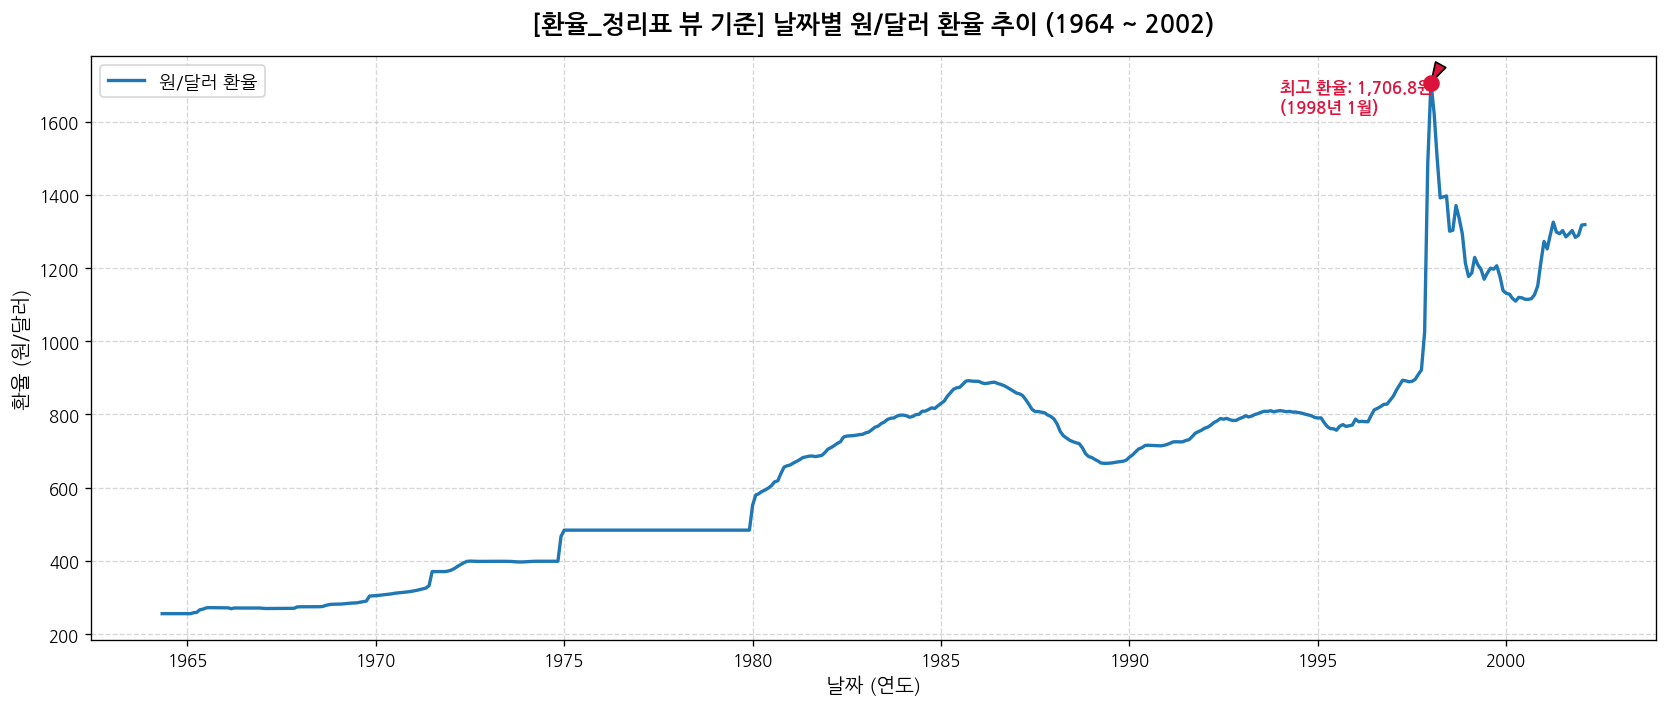

In [2]:
# 1. 데이터베이스 뷰에서 데이터 조회
conn = sqlite3.connect('데이터.db')
query = 'SELECT * FROM 환율_정리표 ORDER BY 연도, 월'
df_rate = pd.read_sql(query, conn)
conn.close()

# 2. 날짜 컬럼 생성 (연도 + 월 -> Datetime)
df_rate['날짜'] = pd.to_datetime(df_rate['연도'].astype(str) + '-' + df_rate['월'].astype(str) + '-01')

# 3. 시각화
plt.figure(figsize=(14, 6), dpi=120)
plt.plot(df_rate['날짜'], df_rate['환율'], color='#1f77b4', linewidth=2, label='원/달러 환율')

# 최고 환율 지점 강조 (1997~1998 IMF 외환위기)
max_row = df_rate.loc[df_rate['환율'].idxmax()]
plt.scatter([max_row['날짜']], [max_row['환율']], color='crimson', s=80, zorder=5)
plt.annotate(
    f"최고 환율: {max_row['환율']:,.1f}원\n({max_row['연도']}년 {max_row['월']}월)",
    xy=(max_row['날짜'], max_row['환율']),
    xytext=(max_row['날짜'] - pd.DateOffset(years=4), max_row['환율'] - 80),
    arrowprops=dict(facecolor='crimson', shrink=0.08, width=1.5, headwidth=7),
    fontsize=10, fontweight='bold', color='crimson'
)

plt.title('[환율_정리표 뷰 기준] 날짜별 원/달러 환율 추이 (1964 ~ 2002)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('날짜 (연도)', fontsize=12)
plt.ylabel('환율 (원/달러)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# X축 눈금 간격 설정 (5년 단위)
plt.gca().xaxis.set_major_locator(mdates.YearLocator(5))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()

# 그래프 이미지 파일로 저장
plt.savefig('환율_정리표_시각화.png', dpi=300, bbox_inches='tight')
print("'환율_정리표_시각화.png' 저장 완료")
plt.show()

## 2. [환율_대통령_통합표 뷰] 역대 정부(대통령)별 환율 변동 추이 시각화 및 저장
- `환율_대통령_통합표` 뷰를 활용해 각 대통령 재임 시기별 환율 변화를 배경색과 라벨로 함께 확인합니다.

'환율_대통령_통합표_시각화.png' 저장 완료


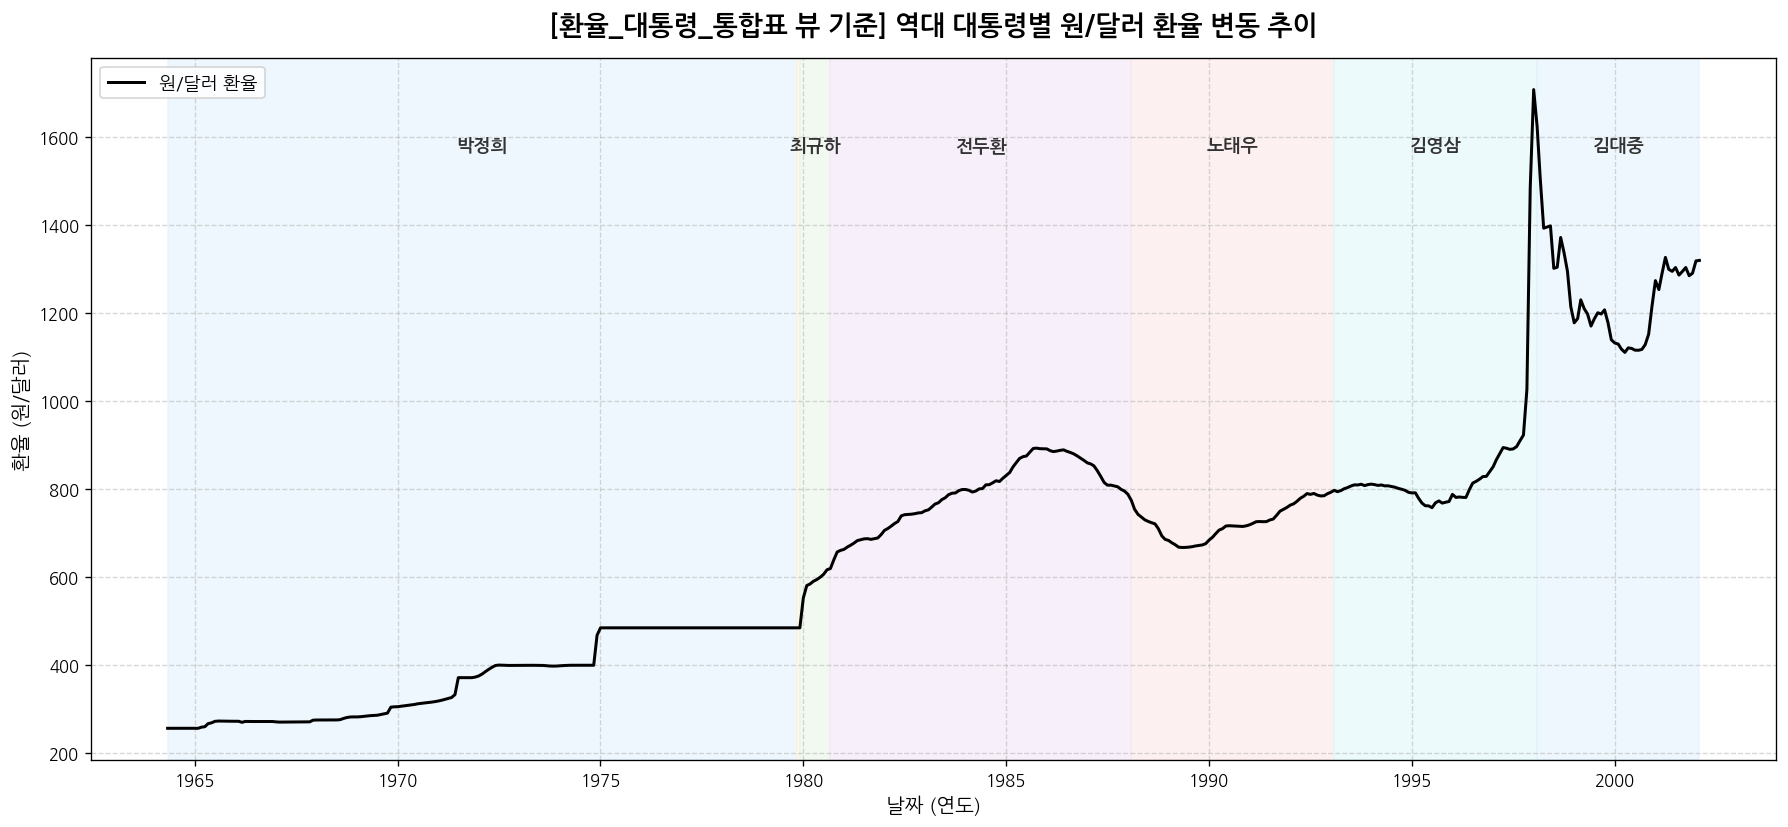

In [3]:
# 1. 데이터베이스 뷰에서 데이터 조회
conn = sqlite3.connect('데이터.db')
query = '''
SELECT DISTINCT 연도, 월, 대통령, 환율 
FROM 환율_대통령_통합표 
ORDER BY 연도, 월
'''
df_pres = pd.read_sql(query, conn)
conn.close()

# 정권 교체 월 중복 처리 및 날짜 변환
df_pres = df_pres.drop_duplicates(subset=['연도', '월'], keep='last').copy()
df_pres['날짜'] = pd.to_datetime(df_pres['연도'].astype(str) + '-' + df_pres['월'].astype(str) + '-01')
df_pres = df_pres.sort_values('날짜').reset_index(drop=True)

# 2. 시각화
fig, ax = plt.subplots(figsize=(15, 7), dpi=120)
ax.plot(df_pres['날짜'], df_pres['환율'], color='black', linewidth=1.8, label='원/달러 환율', zorder=4)

# 대통령별 색상 매핑
presidents = df_pres['대통령'].unique()
colors = ['#E3F2FD', '#FFF3E0', '#E8F5E9', '#F3E5F5', '#FBE9E7', '#E0F7FA']
color_map = {p: colors[i % len(colors)] for i, p in enumerate(presidents)}

# 대통령 재임 구간별 배경 음영 및 라벨 표시
changes = df_pres[df_pres['대통령'] != df_pres['대통령'].shift(1)]
for i in range(len(changes)):
    start_date = changes.iloc[i]['날짜']
    pres_name = changes.iloc[i]['대통령']
    end_date = changes.iloc[i+1]['날짜'] if i+1 < len(changes) else df_pres['날짜'].max()
    
    ax.axvspan(start_date, end_date, color=color_map[pres_name], alpha=0.6, zorder=1)
    mid_date = start_date + (end_date - start_date) / 2
    ax.text(mid_date, df_pres['환율'].max() * 0.92, pres_name, 
            horizontalalignment='center', fontsize=11, fontweight='bold', color='#333333', zorder=5)

ax.set_title('[환율_대통령_통합표 뷰 기준] 역대 대통령별 원/달러 환율 변동 추이', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('날짜 (연도)', fontsize=12)
ax.set_ylabel('환율 (원/달러)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5, zorder=2)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(loc='upper left', fontsize=11)

plt.tight_layout()

# 그래프 이미지 파일로 저장
plt.savefig('환율_대통령_통합표_시각화.png', dpi=300, bbox_inches='tight')
print("'환율_대통령_통합표_시각화.png' 저장 완료")
plt.show()

## 3. [최종 종합 그래프] 대한민국 현대사 핵심 사건 원인 분석 및 종합 시각화
- 7대 핵심 역사적 사건(고정환율제, 제2차 오일쇼크, 3저 호황, 초엔고·1만달러 정책, IMF 외환위기, 금모으기 극복, 닷컴버블 및 9·11 테러)의 **발생 원인과 배경**을 그래프에 직접 주석으로 표시한 최종 결과물입니다.

'최종_환율_역사_시각화.png' 저장 완료


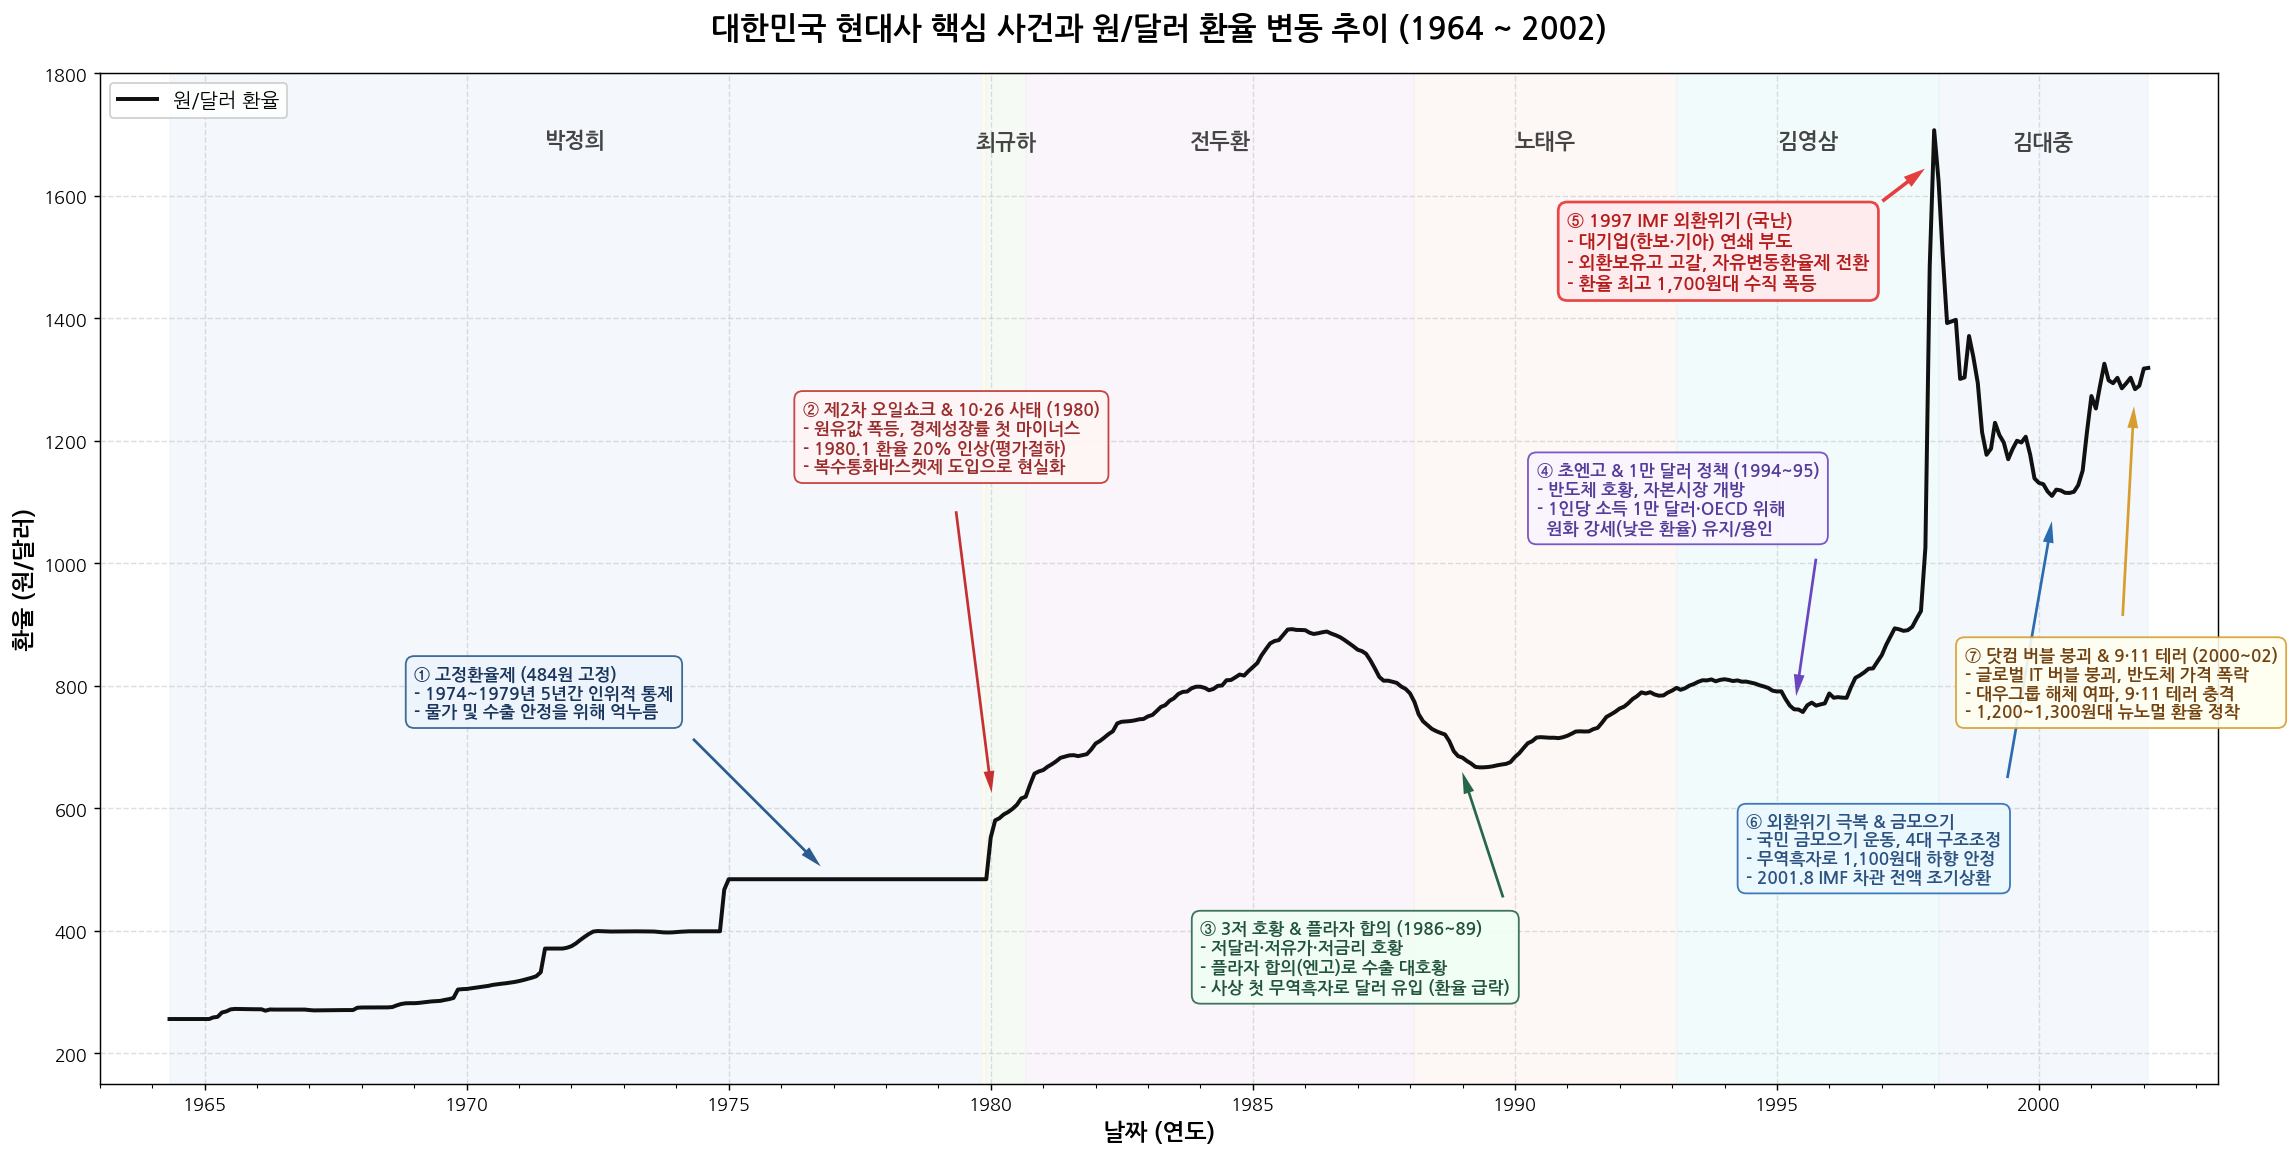

In [4]:
# 1. 데이터베이스 뷰에서 데이터 조회
conn = sqlite3.connect('데이터.db')
query = '''
SELECT DISTINCT 연도, 월, 대통령, 환율 
FROM 환율_대통령_통합표 
ORDER BY 연도, 월
'''
df_pres = pd.read_sql(query, conn)
conn.close()

df = df_pres.drop_duplicates(subset=['연도', '월'], keep='last').copy()
df['날짜'] = pd.to_datetime(df['연도'].astype(str) + '-' + df['월'].astype(str) + '-01')
df = df.sort_values('날짜').reset_index(drop=True)

# 2. 종합 캔버스 생성
fig, ax = plt.subplots(figsize=(18, 9), dpi=130)

# 대통령 재임 기간 배경 음영
presidents = df['대통령'].unique()
colors = ['#EBF3FA', '#FFF8E7', '#EDF7ED', '#F7EDF8', '#FDF0ED', '#E6F8F9']
color_map = {p: colors[i % len(colors)] for i, p in enumerate(presidents)}

changes = df[df['대통령'] != df['대통령'].shift(1)]
for i in range(len(changes)):
    start_date = changes.iloc[i]['날짜']
    pres_name = changes.iloc[i]['대통령']
    end_date = changes.iloc[i+1]['날짜'] if i+1 < len(changes) else df['날짜'].max()
    ax.axvspan(start_date, end_date, color=color_map[pres_name], alpha=0.5, zorder=1)
    mid_date = start_date + (end_date - start_date) / 2
    ax.text(mid_date, 1680, pres_name, 
            horizontalalignment='center', fontsize=12, fontweight='bold', color='#444444', zorder=5)

# 환율 메인 선
ax.plot(df['날짜'], df['환율'], color='#111111', linewidth=2.2, label='원/달러 환율', zorder=3)

# ================= 7대 핵심 사건 주석 (Annotation) =================
# ① 박정희: 고정환율제 (484원 고정)
ax.annotate('① 고정환율제 (484원 고정)\n- 1974~1979년 5년간 인위적 통제\n- 물가 및 수출 안정을 위해 억누름',
            xy=(pd.to_datetime('1977-01-01'), 484), xytext=(pd.to_datetime('1969-01-01'), 750),
            arrowprops=dict(facecolor='#2b5c8f', edgecolor='none', shrink=0.08, width=1.5, headwidth=6),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#eef4fb', edgecolor='#2b5c8f', alpha=0.9),
            fontsize=9.5, fontweight='bold', color='#1a365d')

# ② 최규하: 제2차 오일쇼크 및 10·26 사태 (급등)
ax.annotate('② 제2차 오일쇼크 & 10·26 사태 (1980)\n- 원유값 폭등, 경제성장률 첫 마이너스\n- 1980.1 환율 20% 인상(평가절하)\n- 복수통화바스켓제 도입으로 현실화',
            xy=(pd.to_datetime('1980-02-01'), 580), xytext=(pd.to_datetime('1976-06-01'), 1150),
            arrowprops=dict(facecolor='#c53030', edgecolor='none', shrink=0.08, width=1.5, headwidth=6),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff5f5', edgecolor='#c53030', alpha=0.9),
            fontsize=9.5, fontweight='bold', color='#9b2c2c')

# ③ 전두환 말~노태우: 3저 호황 및 플라자 합의 (급락)
ax.annotate('③ 3저 호황 & 플라자 합의 (1986~89)\n- 저달러·저유가·저금리 호황\n- 플라자 합의(엔고)로 수출 대호황\n- 사상 첫 무역흑자로 달러 유입 (환율 급락)',
            xy=(pd.to_datetime('1988-12-01'), 680), xytext=(pd.to_datetime('1984-01-01'), 300),
            arrowprops=dict(facecolor='#276749', edgecolor='none', shrink=0.08, width=1.5, headwidth=6),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0fff4', edgecolor='#276749', alpha=0.9),
            fontsize=9.5, fontweight='bold', color='#22543d')

# ④ 김영삼 중반: 초엔고 및 1만 달러 달성 정책 (일시 하락)
ax.annotate('④ 초엔고 & 1만 달러 정책 (1994~95)\n- 반도체 호황, 자본시장 개방\n- 1인당 소득 1만 달러·OECD 위해\n  원화 강세(낮은 환율) 유지/용인',
            xy=(pd.to_datetime('1995-05-01'), 760), xytext=(pd.to_datetime('1990-06-01'), 1050),
            arrowprops=dict(facecolor='#6b46c1', edgecolor='none', shrink=0.08, width=1.5, headwidth=6),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#faf5ff', edgecolor='#6b46c1', alpha=0.9),
            fontsize=9.5, fontweight='bold', color='#553c9a')

# ⑤ 김영삼 말~김대중 초: 1997 IMF 외환위기 (수직 폭등)
ax.annotate('⑤ 1997 IMF 외환위기 (국난)\n- 대기업(한보·기아) 연쇄 부도\n- 외환보유고 고갈, 자유변동환율제 전환\n- 환율 최고 1,700원대 수직 폭등',
            xy=(pd.to_datetime('1997-12-01'), 1650), xytext=(pd.to_datetime('1991-01-01'), 1450),
            arrowprops=dict(facecolor='#e53e3e', edgecolor='none', shrink=0.08, width=2, headwidth=7),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffebee', edgecolor='#e53e3e', linewidth=1.5, alpha=0.95),
            fontsize=10, fontweight='bold', color='#b71c1c')

# ⑥ 김대중: 외환위기 극복 및 금모으기 운동 (하향 안정)
ax.annotate('⑥ 외환위기 극복 & 금모으기\n- 국민 금모으기 운동, 4대 구조조정\n- 무역흑자로 1,100원대 하향 안정\n- 2001.8 IMF 차관 전액 조기상환',
            xy=(pd.to_datetime('2000-05-01'), 1110), xytext=(pd.to_datetime('1994-06-01'), 480),
            arrowprops=dict(facecolor='#2b6cb0', edgecolor='none', shrink=0.08, width=1.5, headwidth=6),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#ebf8ff', edgecolor='#2b6cb0', alpha=0.9),
            fontsize=9.5, fontweight='bold', color='#2c5282')

# ⑦ 김대중 후반: 닷컴 버블 붕괴 및 9·11 테러 (반등 및 뉴노멀)
ax.annotate('⑦ 닷컴 버블 붕괴 & 9·11 테러 (2000~02)\n- 글로벌 IT 버블 붕괴, 반도체 가격 폭락\n- 대우그룹 해체 여파, 9·11 테러 충격\n- 1,200~1,300원대 뉴노멀 환율 정착',
            xy=(pd.to_datetime('2001-11-01'), 1290), xytext=(pd.to_datetime('1998-08-01'), 750),
            arrowprops=dict(facecolor='#d69e2e', edgecolor='none', shrink=0.08, width=1.5, headwidth=6),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#fffff0', edgecolor='#d69e2e', alpha=0.9),
            fontsize=9.5, fontweight='bold', color='#744210')

# 레이아웃 및 서식 설정
ax.set_title('대한민국 현대사 핵심 사건과 원/달러 환율 변동 추이 (1964 ~ 2002)', fontsize=17, fontweight='bold', pad=20)
ax.set_xlabel('날짜 (연도)', fontsize=13, fontweight='bold')
ax.set_ylabel('환율 (원/달러)', fontsize=13, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4, zorder=2)
ax.set_ylim(150, 1800)
ax.set_xlim(pd.to_datetime('1963-01-01'), pd.to_datetime('2003-06-01'))

ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.YearLocator(1))

ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
plt.tight_layout()

# 최종 그래프 이미지 파일 저장
plt.savefig('최종_환율_역사_시각화.png', dpi=300, bbox_inches='tight')
print("'최종_환율_역사_시각화.png' 저장 완료")
plt.show()